# 12. A scalar field on a curved background
This is a **classical** field on a **fixed** background: it is neither quantised gravity nor (here) a quantised field. The equation is $(\Box-m^2-\xi R)\phi=0$. On Schwarzschild, with $\phi=e^{-i\omega t}P(\theta)\psi(r)/r$ and $P''+\cot\theta P'=-\ell(\ell+1)P$, it reduces to
$$\frac{d^2\psi}{dr_*^2}+(\omega^2-V)\psi=0,\qquad V=\Bigl(1-\frac{2M}r\Bigr)\Bigl(\frac{\ell(\ell+1)}{r^2}+\frac{2M}{r^3}+m^2\Bigr).$$

In [1]:
from gr_from_scratch.quantum import klein_gordon as kg
print('residual of the claimed reduction (0 means verified):', kg.schwarzschild_radial_reduction())

residual of the claimed reduction (0 means verified): 0


**Boundary conditions.** Ingoing at the horizon ($\psi=e^{-i\omega r_*}$), and at large $r_*$ a decomposition into incoming and outgoing Riccati–Hankel waves. Transmission is $T=1/|A_{\rm in}|^2$ and $1-T-R$ monitors flux conservation.

l=0: max |1-T-R| = 4.4e-09


l=1: max |1-T-R| = 4.4e-09


l=2: max |1-T-R| = 4.4e-09


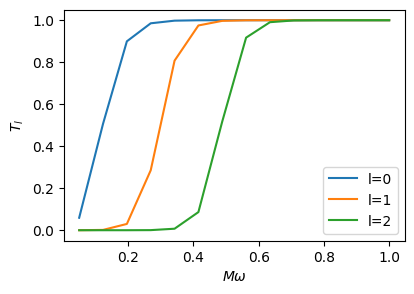

In [2]:
import numpy as np, matplotlib.pyplot as plt
ws = np.linspace(0.05, 1.0, 14)
fig, ax = plt.subplots(figsize=(4.4, 3))
for l in range(3):
    res = [kg.scattering(l, float(w), rstar_max=max(3000., 80/w)) for w in ws]
    ax.plot(ws, [s.transmission for s in res], label=f'l={l}')
    print(f'l={l}: max |1-T-R| = {max(abs(s.flux_residual) for s in res):.1e}')
ax.set(xlabel=r'$M\omega$', ylabel='$T_l$'); ax.legend(); plt.show()

**Analytic limit.** As $\omega\to0$, $T_0\to16M^2\omega^2$ so that $\sigma_{\rm abs}=\pi T_0/\omega^2\to16\pi M^2$, the horizon area. The ratio should approach 1:

In [3]:
for w in (0.05, 0.02, 0.01, 0.005):
    s = kg.scattering(0, w, rstar_max=max(3000., 120/w)); print(f'M w = {w:6.3f}   T0/(16 M^2 w^2) = {s.transmission/(16*w*w):.4f}')

M w =  0.050   T0/(16 M^2 w^2) = 1.4829
M w =  0.020   T0/(16 M^2 w^2) = 1.1570
M w =  0.010   T0/(16 M^2 w^2) = 1.0714
M w =  0.005   T0/(16 M^2 w^2) = 1.0338
